In [1]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score, median_absolute_error

# 1. Carregar dados de regressão
train_df = pd.read_csv('../data/processed/train_regression.csv')
test_df = pd.read_csv('../data/processed/test_regression.csv')

# Identificar a coluna alvo (última coluna ou nome específico)
target_col = train_df.columns[-1]
X_train, y_train = train_df.drop(columns=[target_col]), train_df[target_col]
X_test, y_test = test_df.drop(columns=[target_col]), test_df[target_col]

# 2. Modelo 1: Sistema Especialista (Regressão)
def expert_system_predict_reg(X):
    preds = []
    for _, row in X.iterrows():
        val = row.get('Mental_Wellbeing_Score', 0)
        if val <= -0.5:
            preds.append(8.5)
        elif val <= 0.5:
            preds.append(5.0)
        else:
            preds.append(2.0)
    return np.array(preds)

y_pred_se = expert_system_predict_reg(X_test)

# 3. Modelo 2: Árvore de Decisão com Poda e Busca de Hiperparâmetros (MSE vs MAE)
param_grid_dt = {
    'criterion': ['squared_error', 'absolute_error'],
    'max_depth': [3, 5, 7, 10],
    'min_samples_leaf': [1, 5, 10]
}
grid_dt = GridSearchCV(DecisionTreeRegressor(random_state=42), param_grid_dt, cv=5, scoring='neg_mean_squared_error', n_jobs=-1)
grid_dt.fit(X_train, y_train)
best_dt = grid_dt.best_estimator_
y_pred_dt = best_dt.predict(X_test)

# 4. Modelo 3: Ensemble Learning
rf_reg = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1).fit(X_train, y_train)
gb_reg = GradientBoostingRegressor(n_estimators=100, random_state=42).fit(X_train, y_train)

y_pred_rf = rf_reg.predict(X_test)
y_pred_gb = gb_reg.predict(X_test)

# 5. Função para calcular e exibir métricas
def calcular_metricas(y_true, y_pred, nome_modelo):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mape = mean_absolute_percentage_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    medae = median_absolute_error(y_true, y_pred)
    return {
        'Modelo': nome_modelo, 'MAE': mae, 'MSE': mse, 'RMSE': rmse,
        'MAPE': mape, 'R2': r2, 'MedAE': medae
    }

resultados = [
    calcular_metricas(y_test, y_pred_se, 'Sistema Especialista'),
    calcular_metricas(y_test, y_pred_dt, f'Árvore de Decisão (depth={best_dt.get_depth()})'),
    calcular_metricas(y_test, y_pred_rf, 'Random Forest'),
    calcular_metricas(y_test, y_pred_gb, 'Gradient Boosting')
]

df_res = pd.DataFrame(resultados)
print(df_res.to_string(index=False))
print(f"\nMelhores parâmetros da Árvore de Decisão: {grid_dt.best_params_}")

                     Modelo      MAE       MSE     RMSE      MAPE         R2    MedAE
       Sistema Especialista 5.125803 27.347169 5.229452 17.957764 -24.479259 5.099883
Árvore de Decisão (depth=3) 0.373149  0.225861 0.475249  1.113243   0.789566 0.307964
              Random Forest 0.378913  0.228471 0.477987  1.218478   0.787134 0.332986
          Gradient Boosting 0.365325  0.218926 0.467895  1.194040   0.796028 0.312321

Melhores parâmetros da Árvore de Decisão: {'criterion': 'absolute_error', 'max_depth': 3, 'min_samples_leaf': 5}


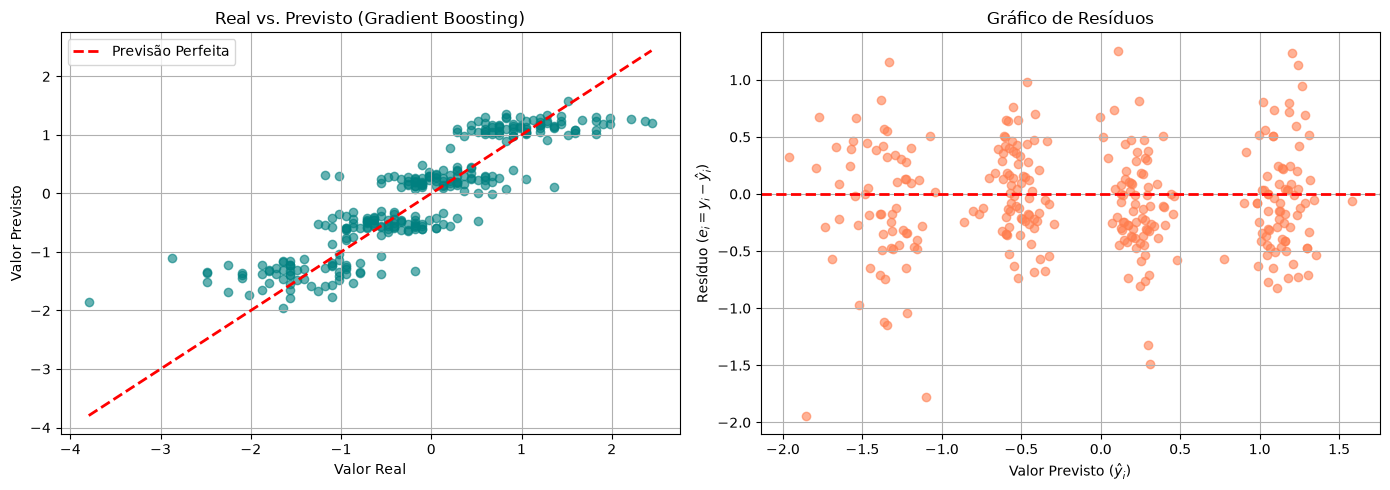

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

# 1. Salvar Tabela de Resultados
os.makedirs('../reports/tables', exist_ok=True)
df_res.to_csv('../reports/tables/resumo_regressao.csv', index=False)

# 2. Análise de Resíduos (Gradient Boosting)
residuos = y_test - y_pred_gb

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Real vs. Previsto
axes[0].scatter(y_test, y_pred_gb, alpha=0.6, color='teal')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Previsão Perfeita')
axes[0].set_xlabel('Valor Real')
axes[0].set_ylabel('Valor Previsto')
axes[0].set_title('Real vs. Previsto (Gradient Boosting)')
axes[0].legend()
axes[0].grid(True)

# Gráfico 2: Resíduos vs. Previsto (com formatação LaTeX correta)
axes[1].scatter(y_pred_gb, residuos, alpha=0.6, color='coral')
axes[1].axhline(y=0, color='r', linestyle='--', lw=2)
axes[1].set_xlabel(r'Valor Previsto ($\hat{y}_i$)')
axes[1].set_ylabel(r'Resíduo ($e_i = y_i - \hat{y}_i$)')
axes[1].set_title('Gráfico de Resíduos')
axes[1].grid(True)

plt.tight_layout()
plt.savefig('../reports/figures/regression_residuals.png', bbox_inches='tight')
plt.show()